# 03 — Baselines com validação walk-forward semanal

Este notebook cria uma referência reproduzível antes de comparar modelos de ML. Cada previsão é emitida em uma origem fixa semanal (sexta-feira) para os dias observados nos sete dias seguintes. O treino usa somente consumos conhecidos antes da origem; as mesmas datas futuras são avaliadas para todos os baselines.

Baselines: último consumo observado, mediana dos cinco consumos recentes, último valor observado para o mesmo dia da semana e mediana dos oito consumos anteriores do mesmo dia da semana. Excesso e falta abaixo são apenas erros de previsão simulados, não sobra/falta operacional observada.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Não localizei a raiz F:/PRODUTO_MESTRADO.")
LINE_ID = "consumo_cardapio_calendario"
LINE_RESULTS = ROOT / "resultados" / "linhas" / LINE_ID
FEATURES_DIR = ROOT / "data" / "experimentos" / LINE_ID / "features"
GOLD_PATH = ROOT / "data" / "gold" / "base_modelagem_consumo_cardapio_calendario_v0.csv"
OUT = LINE_RESULTS / "03_baselines_walk_forward"
OUT.mkdir(parents=True, exist_ok=True)
gold = pd.read_csv(GOLD_PATH, encoding="utf-8-sig")
gold["data"] = pd.to_datetime(gold["data"], errors="raise").dt.normalize()
gold["consumo_total"] = pd.to_numeric(gold["consumo_total"], errors="raise")
gold = gold.sort_values("data").reset_index(drop=True)
print(f"Base Gold: {len(gold)} observações | {gold['data'].min().date()} a {gold['data'].max().date()}")


Base Gold: 503 observações | 2023-02-06 a 2025-12-16


In [2]:
# Origens semanais em sextas-feiras; aquecimento de 60 observações
minimum_history = 60
horizon_days = 7
start_origin = gold["data"].min() + pd.Timedelta(days=1)
end_origin = gold["data"].max()
origins = pd.date_range(start=start_origin, end=end_origin, freq="W-FRI")
prediction_rows = []
fold_rows = []

for fold_id, origin in enumerate(origins, start=1):
    history = gold.loc[gold["data"] < origin].copy()
    future = gold.loc[(gold["data"] > origin) & (gold["data"] <= origin + pd.Timedelta(days=horizon_days)) & gold["data"].dt.dayofweek.lt(5)].copy()
    if len(history) < minimum_history or future.empty:
        continue
    recent = history["consumo_total"].tail(5)
    last_prediction = float(history["consumo_total"].iloc[-1])
    recent_median = float(recent.median())
    fold_rows.append({"fold": fold_id, "origem": origin, "n_treino": len(history), "n_teste": len(future),
                      "primeira_data_teste": future["data"].min(), "ultima_data_teste": future["data"].max()})
    for row in future.itertuples(index=False):
        same_weekday = history.loc[history["data"].dt.dayofweek.eq(row.data.dayofweek), "consumo_total"]
        if same_weekday.empty:
            same_weekday_last = recent_median
            same_weekday_median = recent_median
        else:
            same_weekday_last = float(same_weekday.iloc[-1])
            same_weekday_median = float(same_weekday.tail(8).median())
        predictions = {
            "ultimo_consumo_observado": last_prediction,
            "mediana_ultimos_5_consumos": recent_median,
            "ultimo_mesmo_dia_semana": same_weekday_last,
            "mediana_ultimos_8_mesmo_dia_semana": same_weekday_median,
        }
        for model, prediction in predictions.items():
            prediction_rows.append({"fold": fold_id, "origem": origin, "data": row.data,
                                    "ano": row.data.year, "modelo": model,
                                    "consumo_real": float(row.consumo_total), "previsao": prediction})

predictions = pd.DataFrame(prediction_rows)
folds = pd.DataFrame(fold_rows)
assert not predictions.empty, "Validação não gerou previsões."
date_sets = [set(pd.to_datetime(group["data"])) for _, group in predictions.groupby("modelo")]
assert all(dates == date_sets[0] for dates in date_sets[1:]), "Modelos avaliados em datas diferentes."
assert predictions["previsao"].notna().all() and np.isfinite(predictions["previsao"]).all()
display(folds.head(8))
print(f"Origens avaliadas: {len(folds)} | datas-alvo únicas: {predictions['data'].nunique()} | previsões por modelo: {predictions.groupby('modelo').size().to_dict()}")


,fold,origem,n_treino,n_teste,primeira_data_teste,ultima_data_teste
0,14,2023-05-12,60,5,2023-05-15,2023-05-19
1,15,2023-05-19,65,5,2023-05-22,2023-05-26
2,16,2023-05-26,70,5,2023-05-29,2023-06-02
3,17,2023-06-02,75,3,2023-06-05,2023-06-07
4,18,2023-06-09,79,5,2023-06-12,2023-06-16
5,19,2023-06-16,83,5,2023-06-19,2023-06-23
6,20,2023-06-23,88,5,2023-06-26,2023-06-30
7,21,2023-06-30,93,3,2023-07-03,2023-07-05


Origens avaliadas: 104 | datas-alvo únicas: 439 | previsões por modelo: {'mediana_ultimos_5_consumos': 439, 'mediana_ultimos_8_mesmo_dia_semana': 439, 'ultimo_consumo_observado': 439, 'ultimo_mesmo_dia_semana': 439}


In [3]:
# Métricas de previsão e erro operacional simulado
def summarize(group):
    error = group["previsao"] - group["consumo_real"]
    absolute = error.abs()
    denominator = group["consumo_real"].abs().sum()
    return pd.Series({
        "n_datas": len(group),
        "MAE": absolute.mean(),
        "WAPE_pct": 100 * absolute.sum() / denominator if denominator else np.nan,
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "vies_previsao_menos_real": error.mean(),
        "excesso_previsto_unidades": error.clip(lower=0).sum(),
        "falta_prevista_unidades": (-error).clip(lower=0).sum(),
    })

overall = predictions.groupby("modelo", sort=False).apply(summarize, include_groups=False).reset_index()
by_year = predictions.groupby(["ano", "modelo"], sort=False).apply(summarize, include_groups=False).reset_index()
overall[["MAE", "WAPE_pct", "RMSE", "vies_previsao_menos_real"]] = overall[["MAE", "WAPE_pct", "RMSE", "vies_previsao_menos_real"]].round(3)
by_year[["MAE", "WAPE_pct", "RMSE", "vies_previsao_menos_real"]] = by_year[["MAE", "WAPE_pct", "RMSE", "vies_previsao_menos_real"]].round(3)
display(overall.sort_values("MAE"))
display(by_year.sort_values(["ano", "MAE"]))


,modelo,n_datas,MAE,WAPE_pct,RMSE,vies_previsao_menos_real,excesso_previsto_unidades,falta_prevista_unidades
3,mediana_ultimos_8_mesmo_dia_semana,439.0,25.409,18.654,37.883,3.220,6284.0,4870.5
2,ultimo_mesmo_dia_semana,439.0,27.845,20.442,39.321,-0.027,6106.0,6118.0
1,mediana_ultimos_5_consumos,439.0,28.478,20.907,37.976,0.077,6268.0,6234.0
0,ultimo_consumo_observado,439.0,31.196,22.902,42.223,-10.021,4648.0,9047.0


,ano,modelo,n_datas,MAE,WAPE_pct,RMSE,vies_previsao_menos_real,excesso_previsto_unidades,falta_prevista_unidades
3,2023,mediana_ultimos_8_mesmo_dia_semana,120.0,20.750,19.842,32.484,10.075,1849.5,640.5
0,2023,ultimo_consumo_observado,120.0,24.767,23.683,34.878,-0.617,1449.0,1523.0
1,2023,mediana_ultimos_5_consumos,120.0,25.808,24.679,36.250,0.225,1562.0,1535.0
2,2023,ultimo_mesmo_dia_semana,120.0,27.650,26.440,39.491,1.050,1722.0,1596.0
5,2024,mediana_ultimos_5_consumos,146.0,31.644,19.766,40.617,-1.466,2203.0,2417.0
6,2024,ultimo_mesmo_dia_semana,146.0,31.952,19.958,43.892,-2.349,2161.0,2504.0
4,2024,ultimo_consumo_observado,146.0,32.849,20.519,45.037,-16.890,1165.0,3631.0
7,2024,mediana_ultimos_8_mesmo_dia_semana,146.0,34.154,21.334,47.140,-2.510,2310.0,2676.5
11,2025,mediana_ultimos_8_mesmo_dia_semana,173.0,21.260,15.406,32.162,3.301,2124.5,1553.5
10,2025,ultimo_mesmo_dia_semana,173.0,24.514,17.764,34.868,1.185,2223.0,2018.0


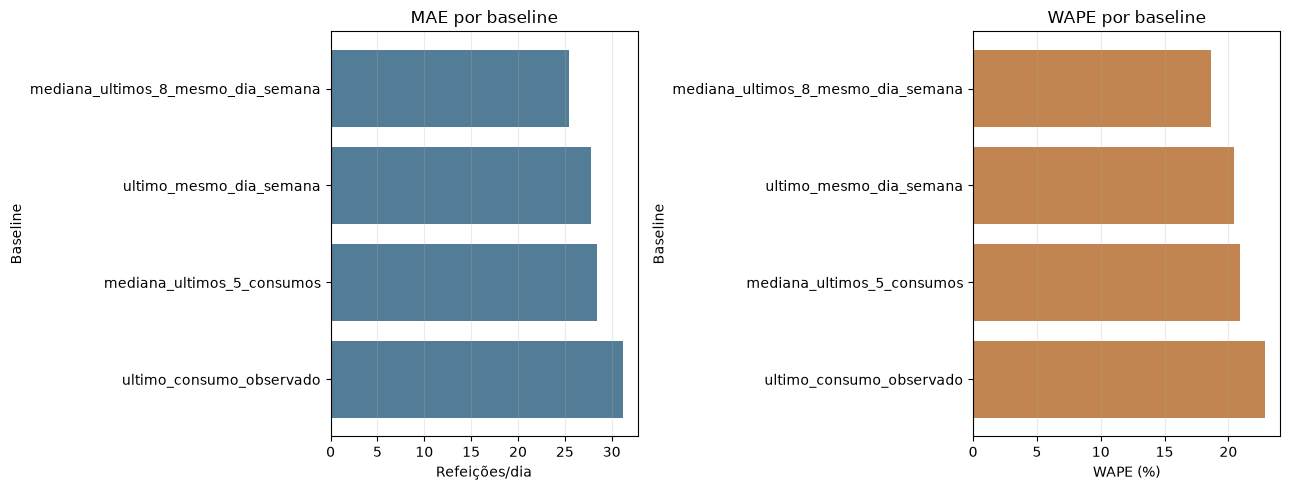

In [4]:
# Gráfico comparativo das métricas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ordered = overall.sort_values("MAE")
axes[0].barh(ordered["modelo"], ordered["MAE"], color="#537D96")
axes[0].invert_yaxis(); axes[0].set(title="MAE por baseline", xlabel="Refeições/dia", ylabel="Baseline"); axes[0].grid(axis="x", alpha=.25)
ordered_wape = overall.sort_values("WAPE_pct")
axes[1].barh(ordered_wape["modelo"], ordered_wape["WAPE_pct"], color="#C28450")
axes[1].invert_yaxis(); axes[1].set(title="WAPE por baseline", xlabel="WAPE (%)", ylabel="Baseline"); axes[1].grid(axis="x", alpha=.25)
fig.tight_layout(); fig.savefig(OUT / "comparacao_baselines_mae_wape.png", dpi=160, bbox_inches="tight"); plt.show()


In [5]:
# Persiste previsões pareadas, folds e métricas
predictions.to_csv(OUT / "previsoes_baselines_pareadas.csv", index=False, encoding="utf-8-sig")
folds.to_csv(OUT / "folds_walk_forward.csv", index=False, encoding="utf-8-sig")
overall.to_csv(OUT / "metricas_gerais.csv", index=False, encoding="utf-8-sig")
by_year.to_csv(OUT / "metricas_por_ano.csv", index=False, encoding="utf-8-sig")
print(f"Resultados salvos em {OUT}")


Resultados salvos em F:\PRODUTO_MESTRADO\resultados\linhas\consumo_cardapio_calendario\03_baselines_walk_forward


## Limites desta etapa

Os baselines usam somente consumo histórico; cardápio e calendário ainda não participam das regras simples. O notebook estabelece referências e mantém previsões pareadas nas mesmas datas. Excesso/falta são desvios previstos em relação ao consumo-alvo, não medições de desperdício nem de atendimento.

O Notebook 04 deverá usar exatamente as origens e datas aqui registradas, treinar nos alvos anteriores a cada origem e construir o bloco de teste com uma origem comum via função temporal do Notebook 02.
